In [1]:
%pip install pandas numpy seaborn scikit-learn nltk lime shap imbalanced-learn
%pip install torch "transformers>=4.40" tf-keras

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ["USE_TF"] = "0"  # evita o conflito do Transformers com o Keras 3

import pandas as pd
import numpy as np
import re
import random
import seaborn as sns
import matplotlib.pyplot as plt
import shap
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from lime.lime_text import LimeTextExplainer

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from imblearn.over_sampling import RandomOverSampler
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

c:\Users\LUIRYS SILVA\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cpu


In [3]:
df = pd.read_csv('../all-data.csv')

In [4]:
df.head()

,sentiment,text
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


In [5]:
df.shape

(4846, 2)

<Axes: xlabel='sentiment', ylabel='count'>

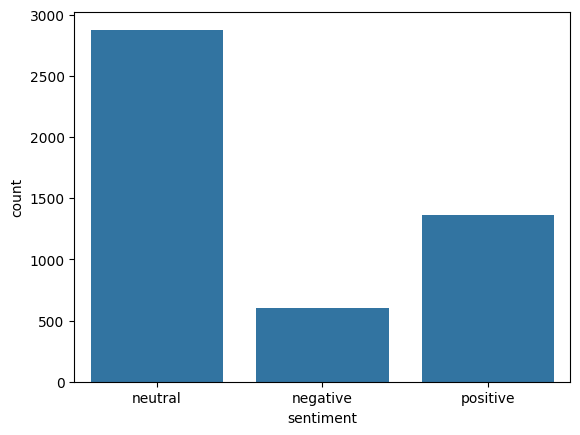

In [6]:
sns.countplot(x='sentiment', data = df)

In [7]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("wordnet")
nltk.download('punkt_tab')

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    tokens = word_tokenize(text)
    stop_words = set(stopwords.words("english"))
    tokens = [word for word in tokens if word not in stop_words]
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(preprocess_text)

# Texto que vai para o DistilBERT: "text" (recomendado) ou "clean_text"
TEXT_COLUMN = "text"

[nltk_data] Downloading package stopwords to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [8]:
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['sentiment'])
le.classes_

array(['negative', 'neutral', 'positive'], dtype=object)

In [9]:
X = df[TEXT_COLUMN]
y = df['label_encoded']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#, stratify=y

# Conferência: o exemplo 499 deve ser o mesmo tweet usado no MLP
print("Índice original do exemplo 499:", X_test.index[499])
print("clean_text (como no MLP):", df.loc[X_test.index[499], "clean_text"])
print("Texto que o DistilBERT verá:", X_test.iloc[499])

Índice original do exemplo 499: 2698
clean_text (como no MLP): preliminary estimation technology park measure square meter
Texto que o DistilBERT verá: Under a preliminary estimation , the technology park will measure about 50,000 square meters .


In [10]:
# Validação = 10% finais do treino, exatamente como validation_split=0.1 do Keras
split_at = int(len(X_train) * (1 - 0.1))
X_tr, X_val = X_train.iloc[:split_at], X_train.iloc[split_at:]
y_tr, y_val = y_train.iloc[:split_at], y_train.iloc[split_at:]
print("Treino:", len(X_tr), "| Validação:", len(X_val), "| Teste:", len(X_test))

Treino: 3488 | Validação: 388 | Teste: 970


Distribuição ANTES do ROS (treino):
neutral     2085
positive     968
negative     435
Name: count, dtype: int64

Distribuição DEPOIS do ROS (treino):
neutral     2085
positive    2085
negative    2085
Name: count, dtype: int64

Treino após ROS: 6255 | Validação: 388 | Teste: 970


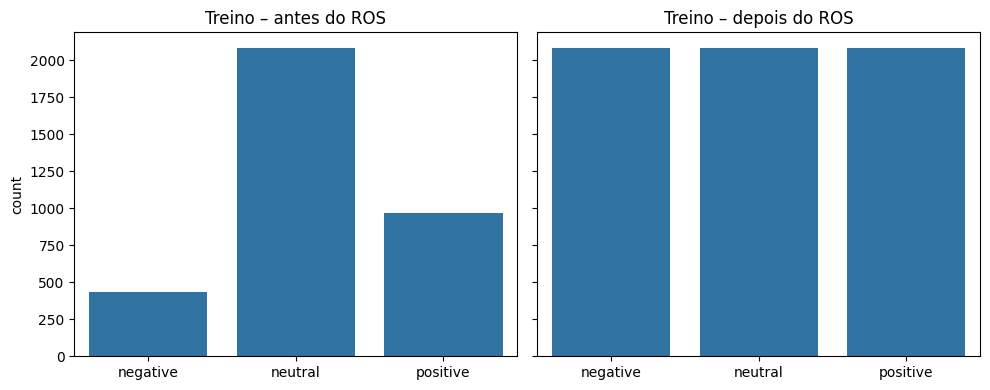

In [11]:
print("Distribuição ANTES do ROS (treino):")
print(pd.Series(le.classes_[y_tr]).value_counts())

ros = RandomOverSampler(sampling_strategy='auto', random_state=42)
X_tr_ros, y_tr_ros = ros.fit_resample(X_tr.to_frame(), y_tr)
X_tr_ros = X_tr_ros[TEXT_COLUMN]

print("\nDistribuição DEPOIS do ROS (treino):")
print(pd.Series(le.classes_[y_tr_ros]).value_counts())
print("\nTreino após ROS:", len(X_tr_ros), "| Validação:", len(X_val), "| Teste:", len(X_test))

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
sns.countplot(x=le.classes_[y_tr], ax=ax[0], order=le.classes_); ax[0].set_title("Treino – antes do ROS")
sns.countplot(x=le.classes_[y_tr_ros], ax=ax[1], order=le.classes_); ax[1].set_title("Treino – depois do ROS")
plt.tight_layout(); plt.show()

**Tokenização**

In [12]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Verificar o tamanho dos tweets em tokens para escolher MAX_LEN
lens = [len(tokenizer.encode(t)) for t in X_train]
print("Percentis 50/95/99/máx:", np.percentile(lens, [50, 95, 99]), max(lens))

MAX_LEN = 64
print(f"Tweets cobertos sem truncar: {np.mean(np.array(lens) <= MAX_LEN):.2%}")

Percentis 50/95/99/máx: [28. 57. 69.] 150
Tweets cobertos sem truncar: 97.94%


In [13]:
class TweetDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, padding="max_length",
                             max_length=MAX_LEN, return_tensors="pt")
        self.labels = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

BATCH_SIZE = 32  # mesmo batch do MLP; reduza para 16 se faltar memória

train_loader = DataLoader(TweetDataset(X_tr_ros, y_tr_ros), batch_size=BATCH_SIZE, shuffle=True)  # shuffle=True: as amostras replicadas pelo ROS ficam agrupadas no fim
val_loader   = DataLoader(TweetDataset(X_val, y_val), batch_size=BATCH_SIZE)

**DistilBERT**

In [14]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: c for i, c in enumerate(le.classes_)},
    label2id={c: i for i, c in enumerate(le.classes_)},
    attn_implementation="eager",   # necessário para extrair os pesos de atenção
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parâmetros: {n_params:,}")

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parâmetros: 66,955,779


In [15]:
# Hiperparâmetros usuais de fine-tuning
EPOCHS = 3
LR = 2e-5

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    tot_loss, correct, n = 0.0, 0, 0
    for batch in tqdm(loader, desc="treino" if train else "validação", leave=False):
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.set_grad_enabled(train):
            out = model(**batch)
            if train:
                optimizer.zero_grad()
                out.loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
        bs = batch["labels"].size(0)
        tot_loss += out.loss.item() * bs
        correct += (out.logits.argmax(-1) == batch["labels"]).sum().item()
        n += bs
    return tot_loss / n, correct / n

history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
best_val_loss, best_state = float("inf"), None

for epoch in range(EPOCHS):
    loss, acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, [loss, acc, val_loss, val_acc]):
        history[k].append(v)
    print(f"Epoch {epoch+1}/{EPOCHS} - accuracy: {acc:.4f} - loss: {loss:.4f} "
          f"- val_accuracy: {val_acc:.4f} - val_loss: {val_loss:.4f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

# Restaura a época com menor val_loss (defina RESTORE_BEST=False para usar a última, como no MLP)
RESTORE_BEST = True
if RESTORE_BEST:
    model.load_state_dict(best_state)
    print("Modelo restaurado para a melhor época (menor val_loss).")

Epoch 1/3 - accuracy: 0.6966 - loss: 0.6582 - val_accuracy: 0.8376 - val_loss: 0.4180


Epoch 2/3 - accuracy: 0.9205 - loss: 0.2285 - val_accuracy: 0.8634 - val_loss: 0.4079


Epoch 3/3 - accuracy: 0.9610 - loss: 0.1326 - val_accuracy: 0.8557 - val_loss: 0.4320
Modelo restaurado para a melhor época (menor val_loss).


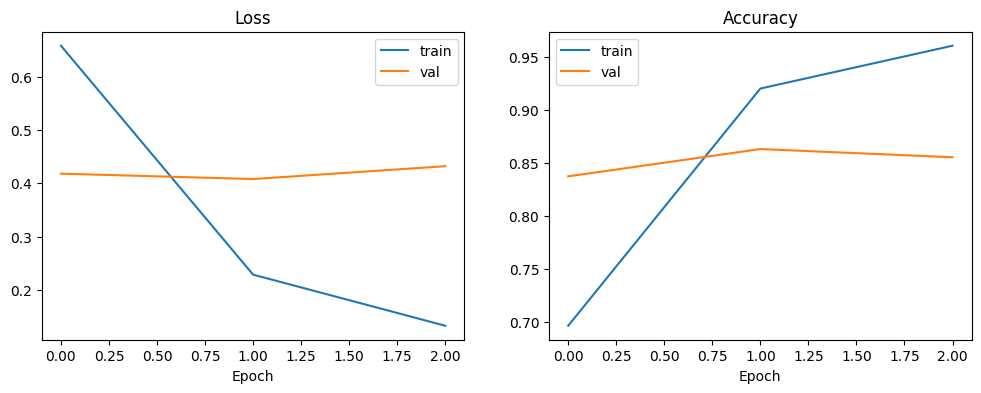

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history["accuracy"], label="train"); ax[1].plot(history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

**Métricas**

In [17]:
@torch.no_grad()
def predict_proba(texts, batch_size=64):
    """Recebe lista de strings e devolve probabilidades (n, 3). Usada nas métricas, no LIME e no SHAP."""
    model.eval()
    texts = [str(t) for t in texts]
    probs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i+batch_size], truncation=True, padding=True,
                        max_length=MAX_LEN, return_tensors="pt").to(device)
        probs.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.vstack(probs)

y_pred = predict_proba(X_test.tolist())
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       0.79      0.86      0.82       110
           1       0.91      0.85      0.88       571
           2       0.76      0.83      0.80       289

    accuracy                           0.84       970
   macro avg       0.82      0.85      0.83       970
weighted avg       0.85      0.84      0.85       970



In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score
def calculate_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1

accuracy, precision, recall, f1 = calculate_metrics(y_test, y_pred_classes)
print(f"Acurácia: {accuracy:.4f}")
print(f"Precisão: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"F1-Score (macro): {f1_score(y_test, y_pred_classes, average='macro'):.4f}  # mais sensível ao desbalanceamento")

Acurácia: 0.8443
Precisão: 0.8500
Recall: 0.8443
F1-Score: 0.8458
F1-Score (macro): 0.8312  # mais sensível ao desbalanceamento


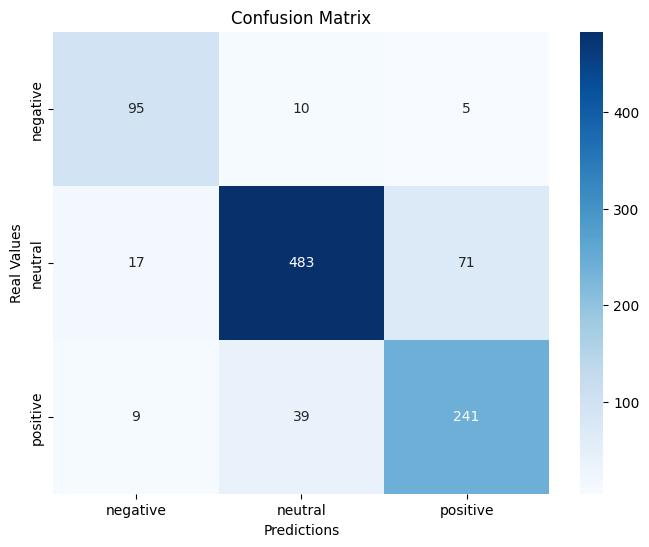

In [19]:
conf_matrix = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predictions")
plt.ylabel("Real Values")
plt.title("Confusion Matrix")
plt.show()

**LIME**

In [20]:
explainer = LimeTextExplainer(class_names=le.classes_)

idx = int(input(f"Digite o número da linha (0 a {len(X_test)-1}): ") or 499)
sample_text = X_test.iloc[idx]
sample_label = y_test.iloc[idx]

pred_probs = predict_proba([sample_text])
pred_class_idx = pred_probs.argmax(axis=1)[0]
pred_class_name = le.classes_[pred_class_idx]

print(f"Número da linha no X_test: {idx}")
print(f"Original text:\n{sample_text}")
print(f"Classe real: {le.classes_[sample_label]}")
print(f"Classe predita: {pred_class_name}")
print("Probabilidades:", pred_probs[0])

# labels=(pred_class_idx,) explica a classe predita (no MLP o LIME explicou a classe 1 por padrão)
explanation = explainer.explain_instance(
    sample_text,
    predict_proba,
    num_features=10,
    labels=(pred_class_idx,)
)

lime_features = explanation.as_list(label=pred_class_idx)
print(lime_features)

Número da linha no X_test: 499
Original text:
Under a preliminary estimation , the technology park will measure about 50,000 square meters .
Classe real: neutral
Classe predita: neutral
Probabilidades: [0.00337171 0.971693   0.02493536]
[(np.str_('measure'), 0.00928597005752917), (np.str_('will'), -0.009269123291238192), (np.str_('estimation'), -0.006247101226087969), (np.str_('square'), 0.005165110966466432), (np.str_('meters'), 0.004449089142469399), (np.str_('Under'), -0.0033820998926969367), (np.str_('about'), 0.003300769372486494), (np.str_('park'), 0.003109597712427672), (np.str_('a'), 0.0029219966505105205), (np.str_('technology'), -0.0026822742930976075)]


Palavras mais importantes e seus pesos:
measure: 0.0093
will: -0.0093
estimation: -0.0062
square: 0.0052
meters: 0.0044
Under: -0.0034
about: 0.0033
park: 0.0031
a: 0.0029
technology: -0.0027


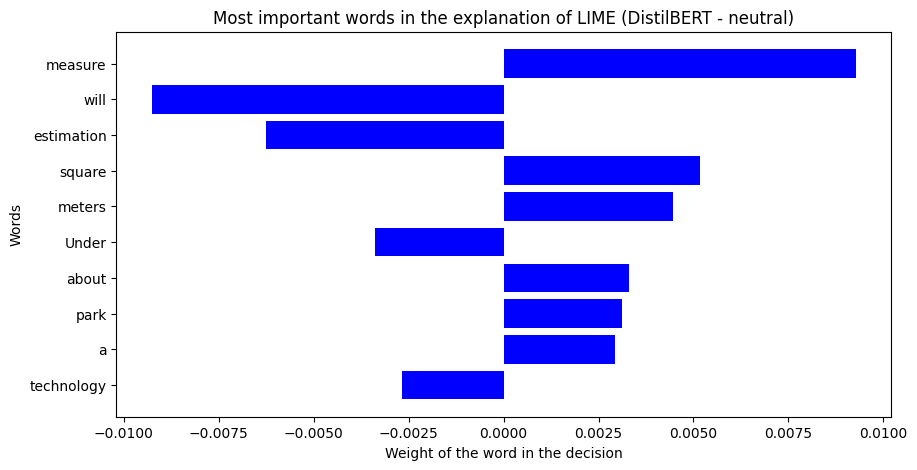

In [21]:
print("Palavras mais importantes e seus pesos:")
for word, weight in lime_features:
    print(f"{word}: {weight:.4f}")

words, weights = zip(*lime_features)
plt.figure(figsize=(10, 5))
plt.barh(words, weights, color="blue")
plt.xlabel("Weight of the word in the decision")
plt.ylabel("Words")
plt.title(f"Most important words in the explanation of LIME (DistilBERT - {pred_class_name})")
plt.gca().invert_yaxis()
plt.show()

**Attention Viz**

In [22]:
lime_idx = 499
sample_text = X_test.iloc[lime_idx]
print("Texto usado na explicação:")
print(sample_text)

enc = tokenizer(sample_text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
model.eval()
with torch.no_grad():
    out = model(**enc, output_attentions=True)

predicted_class_index = out.logits.argmax(-1).item()
print(f"\nClasse prevista: {predicted_class_index} ({le.classes_[predicted_class_index]})")
print("Probabilidades:", torch.softmax(out.logits, -1)[0].cpu().numpy())

# (camadas, cabeças, seq, seq)
att = torch.stack(out.attentions)[:, 0].cpu()
print("Atenções:", tuple(att.shape))

# 1) Última camada: [CLS] -> tokens, média das cabeças
last_cls = att[-1].mean(0)[0].numpy()

# 2) Attention rollout
seq = att.shape[-1]
rollout = torch.eye(seq)
for layer in att:
    a = layer.mean(0) + torch.eye(seq)
    a = a / a.sum(-1, keepdim=True)
    rollout = a @ rollout
rollout_cls = rollout[0].numpy()

tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])

def merge_subwords(tokens, scores):
    """Junta subpalavras (##) em palavras somando os escores e remove [CLS]/[SEP]."""
    words, vals = [], []
    for t, s in zip(tokens, scores):
        if t in ("[CLS]", "[SEP]", "[PAD]"):
            continue
        if t.startswith("##") and words:
            words[-1] += t[2:]; vals[-1] += s
        else:
            words.append(t); vals.append(s)
    return words, np.array(vals)

w_last, v_last = merge_subwords(tokens, last_cls)
w_roll, v_roll = merge_subwords(tokens, rollout_cls)

importancias = pd.DataFrame({"Feature": w_last, "Last layer [CLS]": v_last, "Rollout": v_roll})
importancias = importancias.sort_values(by="Rollout", ascending=False)
print(importancias.head(20))

Texto usado na explicação:
Under a preliminary estimation , the technology park will measure about 50,000 square meters .

Classe prevista: 1 (neutral)
Probabilidades: [0.00337171 0.971693   0.02493536]
Atenções: (6, 12, 19, 19)
        Feature  Last layer [CLS]   Rollout
16            .          0.096882  0.074555
5           the          0.079570  0.036098
4             ,          0.064716  0.035310
9       measure          0.096535  0.030022
1             a          0.059477  0.028746
8          will          0.099153  0.028745
3    estimation          0.075251  0.026845
0         under          0.064107  0.025653
12            ,          0.006939  0.024650
7          park          0.035080  0.024490
2   preliminary          0.086743  0.023784
15       meters          0.017745  0.023403
6    technology          0.013001  0.022399
10        about          0.075105  0.021929
13          000          0.012661  0.019320
14       square          0.013731  0.018113
11           50        

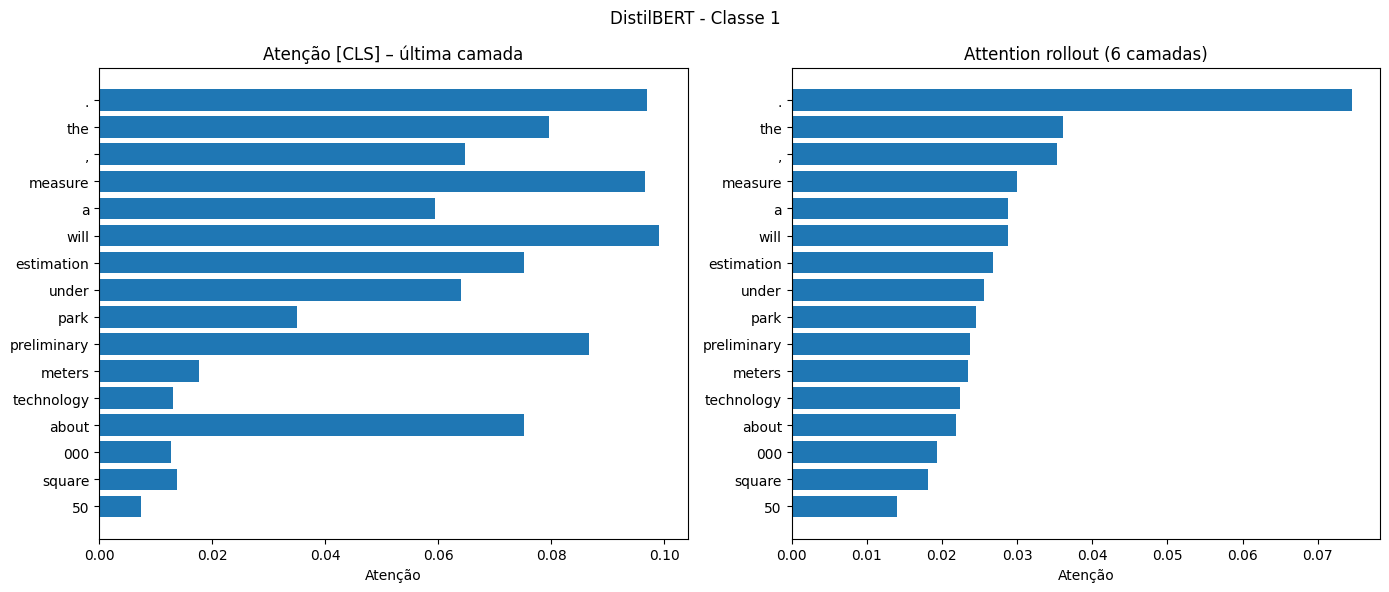

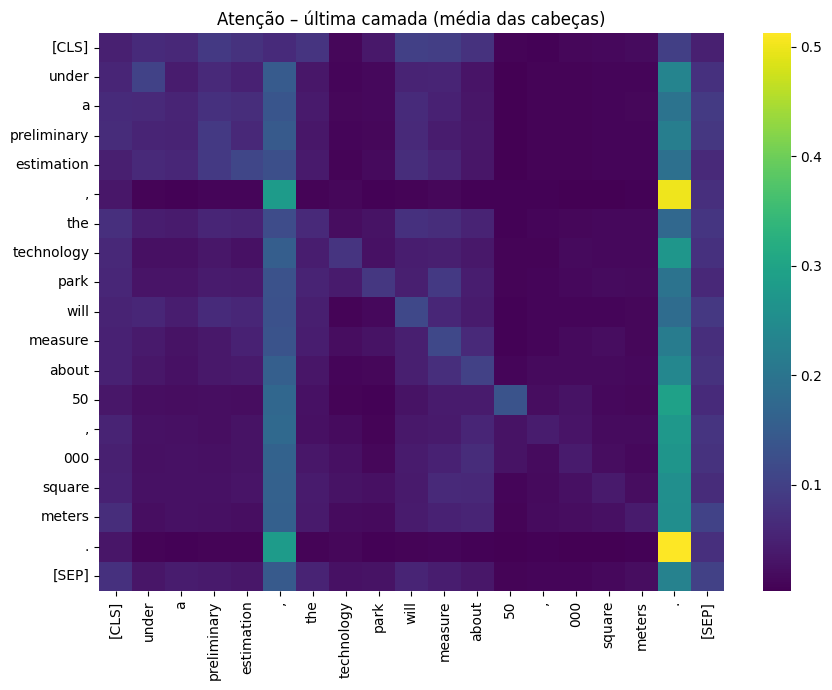

In [23]:
top = importancias.head(20)
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(top["Feature"], top["Last layer [CLS]"])
ax[0].set_title("Atenção [CLS] – última camada"); ax[0].invert_yaxis()
ax[1].barh(top["Feature"], top["Rollout"])
ax[1].set_title("Attention rollout (6 camadas)"); ax[1].invert_yaxis()
for a in ax: a.set_xlabel("Atenção")
fig.suptitle(f"DistilBERT - Classe {predicted_class_index}")
plt.tight_layout(); plt.show()

# Mapa de calor da última camada (média das cabeças)
plt.figure(figsize=(9, 7))
sns.heatmap(att[-1].mean(0).numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis")
plt.title("Atenção – última camada (média das cabeças)")
plt.tight_layout(); plt.show()

**Shapley**

In [24]:
lime_idx = 499
sample_text = X_test.iloc[lime_idx]

pred_class_idx = predict_proba([sample_text]).argmax(axis=1)[0]
print("Classe prevista:", pred_class_idx, le.classes_[pred_class_idx])

masker = shap.maskers.Text(tokenizer)
shap_explainer = shap.Explainer(lambda x: predict_proba(list(x)), masker,
                                output_names=list(le.classes_))

shap_values = shap_explainer([sample_text])

sv = shap_values[0, :, pred_class_idx]
words = np.array(sv.data)
values = np.array(sv.values)
expected_value = float(sv.base_values)

order = np.argsort(np.abs(values))[::-1][:15]
print("Palavras:", words[order])
print("SHAP:", values[order])
print("Valor base:", expected_value)

Classe prevista: 1 neutral


PartitionExplainer explainer: 2it [01:13, 73.26s/it]               

Palavras: ['meters ' 'square ' 'park ' 'measure ' 'technology ' '000 ' 'about '
 'preliminary ' 'will ' 'a ' 'the ' '50' '.' 'Under ' ',']
SHAP: [0.06483985 0.06282732 0.06134898 0.05067977 0.04807083 0.04388974
 0.04255214 0.04137649 0.03780466 0.03109299 0.02590037 0.02217074
 0.01243689 0.01195137 0.00563701]
Valor base: 0.39788129925727844


In [25]:
# Visualização interativa no texto
shap.plots.text(shap_values[0, :, pred_class_idx])

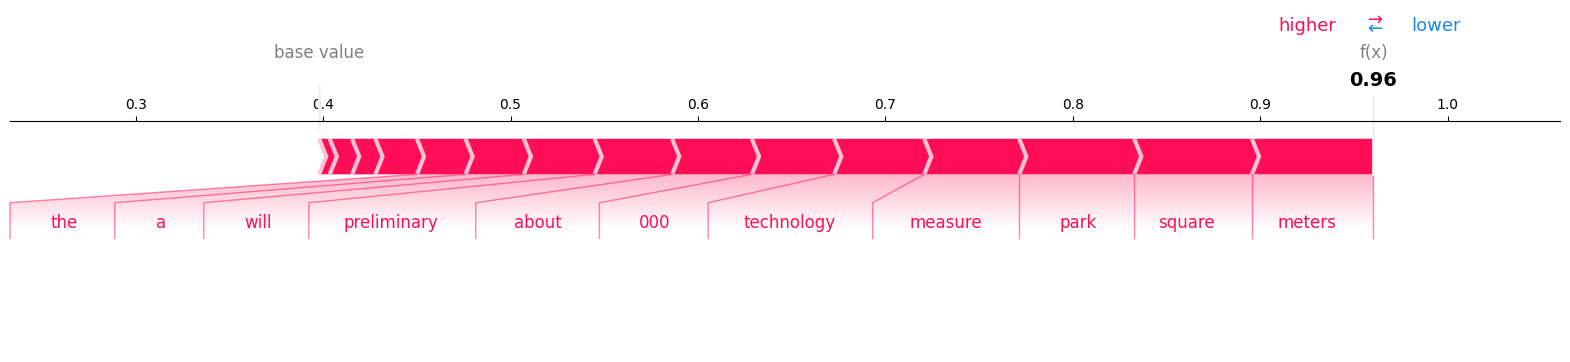

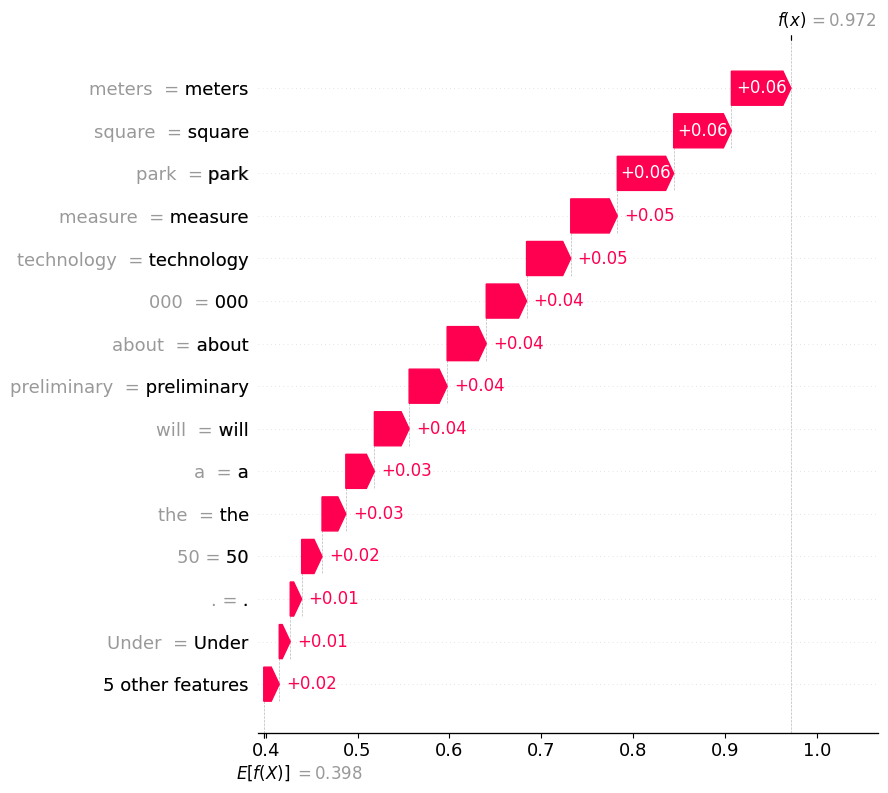

In [26]:
# Force plot (mesmo formato do notebook do MLP)
shap.force_plot(
    base_value=expected_value,
    shap_values=values[order],
    feature_names=[w.strip() for w in words[order]],
    matplotlib=True
)

# Waterfall
shap.plots.waterfall(sv, max_display=15)

**Salvar modelo e resultados** (para comparar os 5 modelos depois)

In [27]:
import json
model.save_pretrained("distilbert_oversampling")
tokenizer.save_pretrained("distilbert_oversampling")

resultados = {
    "modelo": "DistilBERT", "cenario": "oversampling", "n_treino": len(X_tr_ros), "melhor_epoca": int(np.argmin(history["val_loss"])) + 1, "texto": TEXT_COLUMN,
    "accuracy": accuracy, "precision_w": precision, "recall_w": recall, "f1_w": f1,
    "f1_macro": f1_score(y_test, y_pred_classes, average="macro"),
    "epochs": EPOCHS, "lr": LR, "batch_size": BATCH_SIZE, "max_len": MAX_LEN,
}
with open("resultados_distilbert_oversampling.json", "w") as f:
    json.dump(resultados, f, indent=2)
resultados

{'modelo': 'DistilBERT',
 'cenario': 'oversampling',
 'n_treino': 6255,
 'melhor_epoca': 2,
 'texto': 'text',
 'accuracy': 0.8443298969072165,
 'precision_w': 0.8499839843860018,
 'recall_w': 0.8443298969072165,
 'f1_w': 0.8457926248657882,
 'f1_macro': 0.8312278838296988,
 'epochs': 3,
 'lr': 2e-05,
 'batch_size': 32,
 'max_len': 64}